# Movie Recommendation System Project
## Collaborative Filtering, SVD, and Neural Networks

In [3]:
!ls -l /content

total 960
-rw-r--r-- 1 root root 978202 May 24 20:37 ml-latest-small.zip
drwxr-xr-x 1 root root   4096 May 21 13:27 sample_data


In [4]:
import tensorflow as tf
import os
import pandas as pd
import zipfile # Import zipfile module
import tempfile # Import tempfile module for gettempdir

# Define the path to the uploaded MovieLens 100k dataset zip file
# Based on `!ls -l /content` output, the uploaded file is 'ml-latest-small.zip'
movielens_zip_path = '/content/ml-latest-small.zip' # Updated file name

# Define the directory where the dataset will be extracted
# Using a temporary directory for extraction
extract_base_dir = tempfile.gettempdir() # Replaced tf.keras.utils.get_temp_dir() with tempfile.gettempdir()
destination_dir = os.path.join(extract_base_dir, 'movielens_extracted')
os.makedirs(destination_dir, exist_ok=True)

# Extract the zip file using Python's zipfile module
try:
    with zipfile.ZipFile(movielens_zip_path, 'r') as zip_ref:
        zip_ref.extractall(destination_dir)
    print(f"Successfully extracted {movielens_zip_path} to {destination_dir}")

    # Determine the actual path to u.data within the extracted directory
    # The zip usually contains a folder named 'ml-100k' or 'ml-latest-small'
    # Let's adjust for ml-latest-small which typically contains 'links.csv', 'movies.csv', 'ratings.csv', 'README.txt'
    # We are looking for 'ratings.csv' if this is ml-latest-small, not 'u.data'

    # For ml-latest-small, the ratings file is usually 'ratings.csv'
    # The extracted content often sits directly in the destination_dir or a subfolder like 'ml-latest-small'

    ratings_file_name = 'ratings.csv' # Assuming ml-latest-small dataset
    potential_paths = [
        os.path.join(destination_dir, ratings_file_name),
        os.path.join(destination_dir, 'ml-latest-small', ratings_file_name)
    ]

    found_ratings_file = False
    u_data_file_path = None
    for p in potential_paths:
        if os.path.exists(p):
            u_data_file_path = p
            found_ratings_file = True
            break

    if not found_ratings_file:
        print(f"Warning: '{ratings_file_name}' not found at expected paths. Trying to walk the directory.")
        print(f"Contents of {destination_dir}: {os.listdir(destination_dir)}")
        # Try to find ratings.csv by listing all files
        for root, dirs, files in os.walk(destination_dir):
            if ratings_file_name in files:
                u_data_file_path = os.path.join(root, ratings_file_name)
                found_ratings_file = True
                break
        if not found_ratings_file:
            raise FileNotFoundError(f"Could not locate '{ratings_file_name}' file after extraction.")

except FileNotFoundError:
    print(f"Error: The zip file '{movielens_zip_path}' was not found. Please ensure it is uploaded.")
    u_data_file_path = None # Set to None to prevent subsequent errors
except Exception as e:
    print(f"An error occurred during extraction: {e}")
    u_data_file_path = None

# Store this path in a variable that can be accessed by subsequent cells.
# Only store if u_data_file_path was successfully determined
if u_data_file_path:
    %store u_data_file_path
    print(f"Ratings file path stored: {u_data_file_path}")
else:
    print("Could not determine ratings file path. Subsequent cells might fail.")

Successfully extracted /content/ml-latest-small.zip to /tmp/movielens_extracted
Stored 'u_data_file_path' (str)
Ratings file path stored: /tmp/movielens_extracted/ml-latest-small/ratings.csv


In [5]:
 !pip install pandas matplotlib scikit-learn scikit-surprise tensorflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 4.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp312-cp312-linux_x86_64.whl size=2557226 sha256=ac190e1d5a7a15faf8df08975685aeaeb3af42236c9f0e6cc3f11b76556ebb22
  Stored in directory: /root/.cache/pip/wheels/75/fa/bc/739bc2cb1fbaab6061854e6cfbb81a0ae52c92a502a7fa454b
Successfully built scikit-surprise


In [6]:
pip install scikit-surprise

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity

# from surprise import Dataset, Reader, SVD
# from surprise.model_selection import train_test_split as surprise_split
# from surprise.accuracy import rmse

from sklearn.model_selection import train_test_split # For general train/test splitting
from sklearn.decomposition import TruncatedSVD # For SVD implementation
from sklearn.metrics import mean_squared_error # For RMSE calculation
import math # For sqrt in RMSE

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, Flatten, Dense, Concatenate, Dropout
from tensorflow.keras.optimizers import Adam

In [8]:
columns = ['user_id', 'item_id', 'rating', 'timestamp']
# Retrieve the stored path to u.data (now potentially ratings.csv)
%store -r u_data_file_path

# Check if u_data_file_path is set and valid before reading
if 'u_data_file_path' in locals() and u_data_file_path is not None and os.path.exists(u_data_file_path):
    # The ml-latest-small dataset typically uses 'ratings.csv' with comma separation.
    # For ml-100k, it was 'u.data' with tab separation.
    # We need to adapt the separator based on the expected file type.

    # Assuming if the path ends with .csv, it's comma-separated, otherwise tab-separated.
    separator = ',' if u_data_file_path.endswith('.csv') else '\t'

    df = pd.read_csv(u_data_file_path, sep=separator, names=columns, header=0 if u_data_file_path.endswith('.csv') else None)
    display(df.head())
else:
    print(f"Error: Ratings file path not found or does not exist, or was not set: {u_data_file_path}")
    print("Please ensure the dataset was uploaded and extracted correctly in the previous step.")

,user_id,item_id,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [9]:
print('Number of Ratings:', len(df))
print('Number of Users:', df['user_id'].nunique())
print('Number of Movies:', df['item_id'].nunique())

Number of Ratings: 100836
Number of Users: 610
Number of Movies: 9724


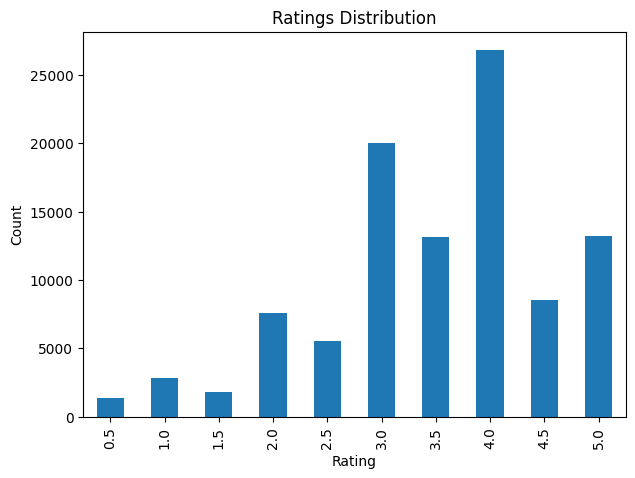

In [10]:
plt.figure(figsize=(7,5))
df['rating'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Ratings Distribution')
plt.show()

In [11]:
user_item_matrix = df.pivot_table(index='user_id', columns='item_id', values='rating')
user_item_matrix.head()

item_id,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
user_id,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
filled_matrix = user_item_matrix.fillna(0)
user_similarity = cosine_similarity(filled_matrix)
user_similarity_df = pd.DataFrame(user_similarity, index=user_item_matrix.index, columns=user_item_matrix.index)
user_similarity_df.head()

user_id,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
user_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.027283,0.059720,0.194395,0.129080,0.128152,0.158744,0.136968,0.064263,0.016875,...,0.080554,0.164455,0.221486,0.070669,0.153625,0.164191,0.269389,0.291097,0.093572,0.145321
2,0.027283,1.000000,0.000000,0.003726,0.016614,0.025333,0.027585,0.027257,0.000000,0.067445,...,0.202671,0.016866,0.011997,0.000000,0.000000,0.028429,0.012948,0.046211,0.027565,0.102427
3,0.059720,0.000000,1.000000,0.002251,0.005020,0.003936,0.000000,0.004941,0.000000,0.000000,...,0.005048,0.004892,0.024992,0.000000,0.010694,0.012993,0.019247,0.021128,0.000000,0.032119
4,0.194395,0.003726,0.002251,1.000000,0.128659,0.088491,0.115120,0.062969,0.011361,0.031163,...,0.085938,0.128273,0.307973,0.052985,0.084584,0.200395,0.131746,0.149858,0.032198,0.107683
5,0.129080,0.016614,0.005020,0.128659,1.000000,0.300349,0.108342,0.429075,0.000000,0.030611,...,0.068048,0.418747,0.110148,0.258773,0.148758,0.106435,0.152866,0.135535,0.261232,0.060792


In [13]:
def recommend_user_based(user_id, n_recommendations=5):
    # Sort similar users by similarity score in descending order, excluding the user itself
    # Taking top 5 similar users (can be adjusted)
    similar_users = user_similarity_df[user_id].sort_values(ascending=False).drop(user_id)[0:5]
    similar_users_ids = similar_users.index

    # Get ratings of similar users
    # Use .reindex to handle cases where a similar user might not have ratings for all items
    similar_users_ratings = user_item_matrix.loc[similar_users_ids]

    # Calculate weighted average of similar users' ratings
    # For simplicity, we are taking a simple mean here; weighted mean would be more advanced
    mean_ratings = similar_users_ratings.mean(axis=0)

    # Get movies already watched by the target user
    watched_movies = user_item_matrix.loc[user_id].dropna().index

    # Filter out movies already watched by the target user from recommendations
    recommendations = mean_ratings.drop(watched_movies, errors='ignore') # 'ignore' to prevent error if a movie is not in index

    # Sort the remaining recommendations in descending order
    recommendations = recommendations.sort_values(ascending=False)

    return recommendations.head(n_recommendations)

# Test the function for user_id = 1
print(f"Recommendations for User 1:\n{recommend_user_based(1)}")

Recommendations for User 1:
item_id
1591    5.0
1663    5.0
6539    5.0
6659    5.0
6820    5.0
dtype: float64


In [14]:
item_similarity = cosine_similarity(filled_matrix.T)
item_similarity_df = pd.DataFrame(item_similarity, index=user_item_matrix.columns, columns=user_item_matrix.columns)
item_similarity_df.head()

item_id,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
item_id,,,,,,,,,,,,,,,,,,,,,
1,1.000000,0.410562,0.296917,0.035573,0.308762,0.376316,0.277491,0.131629,0.232586,0.395573,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.410562,1.000000,0.282438,0.106415,0.287795,0.297009,0.228576,0.172498,0.044835,0.417693,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.296917,0.282438,1.000000,0.092406,0.417802,0.284257,0.402831,0.313434,0.304840,0.242954,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.035573,0.106415,0.092406,1.000000,0.188376,0.089685,0.275035,0.158022,0.000000,0.095598,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.308762,0.287795,0.417802,0.188376,1.000000,0.298969,0.474002,0.283523,0.335058,0.218061,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [15]:
# Split the original DataFrame into training and testing sets for SVD
train_df_svd, test_df_svd = train_test_split(df, test_size=0.2, random_state=42)

# Create user-item matrices for training
# We need to ensure all users and items are represented in the matrix,
# even if they only appear in the test set, for consistent dimensions.
all_users = df['user_id'].unique()
all_items = df['item_id'].unique()

# Initialize training user-item matrix with NaNs
train_user_item_matrix_svd = pd.DataFrame(np.nan, index=all_users, columns=all_items)

# Fill with ratings from train_df_svd
for _, row in train_df_svd.iterrows():
    train_user_item_matrix_svd.loc[row['user_id'], row['item_id']] = row['rating']

# For TruncatedSVD, a common approach is to fill NaNs with the global mean rating from the training data.
global_mean_rating_train = train_df_svd['rating'].mean()
train_user_item_matrix_filled = train_user_item_matrix_svd.fillna(global_mean_rating_train)

# Convert to numpy array
R_train = train_user_item_matrix_filled.values

# Apply TruncatedSVD
k = 50 # Number of latent features, this is a tunable parameter
svd_model = TruncatedSVD(n_components=k, random_state=42)

# Fit SVD model on the training data and reconstruct the matrix
# svd_model.fit_transform(R_train) gives U * Sigma
# svd_model.components_ gives V^T
# Reconstructed matrix = (U * Sigma) @ V^T
U_train = svd_model.fit_transform(R_train)
Vt_train = svd_model.components_
predicted_ratings_matrix = np.dot(U_train, Vt_train)

# Convert predicted ratings back to a DataFrame for easy indexing
predicted_ratings_df_svd = pd.DataFrame(predicted_ratings_matrix,
                                        index=train_user_item_matrix_svd.index,
                                        columns=train_user_item_matrix_svd.columns)

# Evaluate RMSE on the test set
actual_ratings = []
predicted_ratings_svd = []

# Iterate through the test_df_svd to get actual and predicted ratings
for _, row in test_df_svd.iterrows():
    user_id = row['user_id']
    item_id = row['item_id']
    actual_rating = row['rating']

    if user_id in predicted_ratings_df_svd.index and item_id in predicted_ratings_df_svd.columns:
        predicted_rating = predicted_ratings_df_svd.loc[user_id, item_id]
        actual_ratings.append(actual_rating)
        predicted_ratings_svd.append(predicted_rating)
    else:
        # If a user/item from the test set was not in the training set,
        # a fallback strategy (e.g., global mean) would be used in a full system.
        # For this evaluation, we'll simply skip these for now.
        pass

if len(actual_ratings) > 0:
    rmse_svd = math.sqrt(mean_squared_error(actual_ratings, predicted_ratings_svd))
    print(f"SVD (TruncatedSVD) Model RMSE on test set: {rmse_svd}")
else:
    print("No common user-item pairs found in test set for SVD evaluation.")

SVD (TruncatedSVD) Model RMSE on test set: 1.010655579266403


In [19]:
num_users = df['user_id'].max() + 1 # Use max() + 1 to account for 0-based indexing and highest ID
num_items = df['item_id'].max() + 1 # Use max() + 1 to account for 0-based indexing and highest ID

# Split the data into training and testing sets for the Keras model
X_users_train, X_users_test, X_items_train, X_items_test, y_train, y_test = train_test_split(
    df['user_id'].values,
    df['item_id'].values,
    df['rating'].values,
    test_size=0.2, # 20% for testing
    random_state=42 # for reproducibility
)

print(f"Training set size: {len(y_train)}")
print(f"Testing set size: {len(y_test)}")
print(f"Max User ID: {df['user_id'].max()}, Num Users for embedding: {num_users}")
print(f"Max Item ID: {df['item_id'].max()}, Num Items for embedding: {num_items}")

Training set size: 80668
Testing set size: 20168
Max User ID: 610, Num Users for embedding: 611
Max Item ID: 193609, Num Items for embedding: 193610


In [20]:
user_input = Input(shape=[1])
item_input = Input(shape=[1])
user_embedding = Embedding(input_dim=num_users, output_dim=50)(user_input)
item_embedding = Embedding(input_dim=num_items, output_dim=50)(item_input)
user_vec = Flatten()(user_embedding)
item_vec = Flatten()(item_embedding)
concat = Concatenate()([user_vec, item_vec])
dense1 = Dense(128, activation='relu')(concat)
drop1 = Dropout(0.2)(dense1)
dense2 = Dense(64, activation='relu')(drop1)
output = Dense(1)(dense2)
model = Model([user_input, item_input], output)
model.compile(loss='mse', optimizer=Adam(learning_rate=0.001), metrics=['mae'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 50)     │     30,550 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 1, 50)     │  9,680,500 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 50)        │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 50)        │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 100)       │          0 │ flatten_2[0][0],  │
│ (Concatenate)       │                   │            │ flatten_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     12,928 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         65 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,732,299 (37.13 MB)

 Trainable params: 9,732,299 (37.13 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history = model.fit(
    [X_users_train, X_items_train],
    y_train,
    batch_size=64,
    epochs=5,
    validation_split=0.2 # Use a validation split from the training data
)

Epoch 1/5
1009/1009 ━━━━━━━━━━━━━━━━━━━━ 133s 130ms/step - loss: 1.2389 - mae: 0.8168 - val_loss: 0.8262 - val_mae: 0.7158
Epoch 2/5
1009/1009 ━━━━━━━━━━━━━━━━━━━━ 142s 131ms/step - loss: 0.7417 - mae: 0.6657 - val_loss: 0.7905 - val_mae: 0.6921
Epoch 3/5
1009/1009 ━━━━━━━━━━━━━━━━━━━━ 142s 131ms/step - loss: 0.6856 - mae: 0.6358 - val_loss: 0.7786 - val_mae: 0.6743
Epoch 4/5
1009/1009 ━━━━━━━━━━━━━━━━━━━━ 143s 132ms/step - loss: 0.6435 - mae: 0.6144 - val_loss: 0.7825 - val_mae: 0.6818
Epoch 5/5
1009/1009 ━━━━━━━━━━━━━━━━━━━━ 157s 147ms/step - loss: 0.6005 - mae: 0.5904 - val_loss: 0.7993 - val_mae: 0.6850


In [22]:
model.save('recommender_model.keras')
print("Model saved as 'recommender_model.keras'")

Model saved as 'recommender_model.keras'
